# TMDB Movie Data Analysis with PySpark

In [1]:
import os
import sys

# work from the project folder so data/ and figures/ are found
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

%matplotlib inline
from dotenv import load_dotenv
from pyspark.sql import functions as F

from src.spark_session import get_spark
from src.fetch_movies import fetch_movies
from src.clean_movies import clean_dataframe, inspect_columns, add_metrics
from src.validate_clean_data import save_clean_data
from src.explore_movies import print_basic_info
from src.analyze_kpis import all_kpis
from src.search_bruce_willis import find_bruce_willis
from src.search_uma_thurman import find_uma_thurman
from src.compare_franchises import compare_franchise_vs_standalone
from src.analyze_franchises import analyze_franchise_performance
from src.analyze_directors import analyze_director_performance
from src import visualize as viz

## Start Spark

Spark runs in **local mode** (`local[*]`), using all the CPU cores of this computer. While it runs, the Spark UI is at http://localhost:4040.

In [2]:
spark = get_spark()
print("Spark version:", spark.version)

Spark version: 4.3.0


## 1. Fetch the data

In [3]:
MOVIE_IDS = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]

load_dotenv()
raw_df = fetch_movies(spark, MOVIE_IDS, os.getenv("TMDB_API_KEY"))
raw_df.printSchema()

2026-11-04 15:13:19,584 | WARNING | Movie 0 not found (404), skipping
2026-11-04 15:13:20,785 | INFO | Fetched: Avengers: Endgame
2026-11-04 15:13:22,274 | INFO | Fetched: Avatar
2026-11-04 15:13:23,354 | INFO | Fetched: Star Wars: The Force Awakens
2026-11-04 15:13:24,613 | INFO | Fetched: Avengers: Infinity War
2026-11-04 15:13:25,726 | INFO | Fetched: Titanic
2026-11-04 15:13:26,764 | INFO | Fetched: Jurassic World
2026-11-04 15:13:27,830 | INFO | Fetched: The Lion King
2026-11-04 15:13:29,211 | INFO | Fetched: The Avengers
2026-11-04 15:13:30,291 | INFO | Fetched: Furious 7
2026-11-04 15:13:31,454 | INFO | Fetched: Avengers: Age of Ultron
2026-11-04 15:13:32,659 | INFO | Fetched: Black Panther
2026-11-04 15:13:33,818 | INFO | Fetched: Harry Potter and the Deathly Hallows: Part 2
2026-11-04 15:13:35,247 | INFO | Fetched: Star Wars: The Last Jedi
2026-11-04 15:13:36,417 | INFO | Fetched: Frozen II
2026-11-04 15:13:37,562 | INFO | Fetched: Jurassic World: Fallen Kingdom
2026-11-04 15:

root
 |-- adult: boolean (nullable = true)
 |-- backdrop_path: string (nullable = true)
 |-- belongs_to_collection: struct (nullable = true)
 |    |-- backdrop_path: string (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- name: string (nullable = true)
 |    |-- poster_path: string (nullable = true)
 |-- budget: long (nullable = true)
 |-- credits: struct (nullable = true)
 |    |-- cast: array (nullable = true)
 |    |    |-- element: struct (containsNull = true)
 |    |    |    |-- adult: boolean (nullable = true)
 |    |    |    |-- cast_id: long (nullable = true)
 |    |    |    |-- character: string (nullable = true)
 |    |    |    |-- credit_id: string (nullable = true)
 |    |    |    |-- gender: long (nullable = true)
 |    |    |    |-- id: long (nullable = true)
 |    |    |    |-- known_for_department: string (nullable = true)
 |    |    |    |-- name: string (nullable = true)
 |    |    |    |-- order: long (nullable = true)
 |    |    |    |-- original_nam

## 2. Clean and transform

Follows the 11 cleaning steps in the brief. Nested columns are flattened with Spark's built-in array functions (`transform`, `filter`, `concat_ws`) instead of Python loops.

In [4]:
clean_df = clean_dataframe(raw_df)
clean_df.show(5)

Rows and columns before cleaning: 18 28
Rows and columns after cleaning: 18 22
+-----+--------------------+--------------------+------------+--------------------+---------------------+-----------------+-----------+------------+--------------------+--------------------+----------+------------+----------+-------+--------------------+--------------------+--------------------+--------------------+---------+-------------+---------+
|   id|               title|             tagline|release_date|              genres|belongs_to_collection|original_language|budget_musd|revenue_musd|production_companies|production_countries|vote_count|vote_average|popularity|runtime|            overview|    spoken_languages|         poster_path|                cast|cast_size|     director|crew_size|
+-----+--------------------+--------------------+------------+--------------------+---------------------+-----------------+-----------+------------+--------------------+--------------------+----------+------------+---

### Inspect the extracted columns (Spark version of `value_counts()`)

In [5]:
inspect_columns(clean_df)


--- belongs_to_collection ---
+------------------------+-----+
|belongs_to_collection   |count|
+------------------------+-----+
|The Avengers Collection |4    |
|Frozen Collection       |2    |
|Jurassic Park Collection|2    |
|Star Wars Collection    |2    |
|Avatar Collection       |1    |
+------------------------+-----+
only showing top 5 rows

--- genres ---
+---------------+-----+
|genres         |count|
+---------------+-----+
|Adventure      |15   |
|Science Fiction|10   |
|Action         |10   |
|Family         |5    |
|Fantasy        |4    |
+---------------+-----+
only showing top 5 rows

--- production_countries ---
+------------------------+-----+
|production_countries    |count|
+------------------------+-----+
|United States of America|18   |
|United Kingdom          |2    |
+------------------------+-----+


--- production_companies ---
+-----------------------------+-----+
|production_companies         |count|
+-----------------------------+-----+
|Marvel Studios    

### Save and check the cleaned data

In [6]:
save_clean_data(spark, clean_df)

Saved cleaned data to: data/processed/tmdb_movies_clean.parquet and data/processed/tmdb_movies_clean.csv
Rows and columns: 18 22
Columns in the right order: True
Duplicate ids: 0
Missing titles: 0


### Add analysis columns

Profit, ROI, franchise flag and release year. The result is cached because every step below reuses it.

In [7]:
df = add_metrics(clean_df).cache()
print_basic_info(df)

--- First 5 Movies ---
+--------------------------------------------+------------+-----------+------------+------------+
|title                                       |release_year|budget_musd|revenue_musd|vote_average|
+--------------------------------------------+------------+-----------+------------+------------+
|Titanic                                     |1997        |200.0      |2264.162353 |7.902       |
|Harry Potter and the Deathly Hallows: Part 2|2011        |125.0      |1341.511219 |8.082       |
|Avatar                                      |2009        |237.0      |2923.706026 |7.611       |
|The Avengers                                |2012        |220.0      |1518.815515 |8.083       |
|Avengers: Age of Ultron                     |2015        |235.0      |1405.403694 |7.278       |
+--------------------------------------------+------------+-----------+------------+------------+
only showing top 5 rows
--- Numeric Summary ---
+-------+------------------+------------------+

## 3. KPIs: best and worst movies

`rank_movies()` ranks any column with a window function (`row_number`), with optional minimum votes and budget. ROI is calculated with a Spark UDF (`roi_udf`).

In [8]:
for name, ranking in all_kpis(df).items():
    print(name)
    ranking.show(truncate=False)

Highest Revenue
+----+----------------------------+------------+
|rank|title                       |revenue_musd|
+----+----------------------------+------------+
|1   |Avengers: Endgame           |2942.19     |
|2   |Avatar                      |2923.71     |
|3   |Titanic                     |2264.16     |
|4   |Star Wars: The Force Awakens|2068.22     |
|5   |Avengers: Infinity War      |2052.42     |
+----+----------------------------+------------+

Highest Budget
+----+----------------------------+-----------+
|rank|title                       |budget_musd|
+----+----------------------------+-----------+
|1   |Avengers: Endgame           |356.0      |
|2   |Avengers: Infinity War      |300.0      |
|3   |Star Wars: The Last Jedi    |300.0      |
|4   |The Lion King               |260.0      |
|5   |Star Wars: The Force Awakens|245.0      |
+----+----------------------------+-----------+

Highest Profit
+----+----------------------------+-----------+
|rank|title                    

## 4. Searches

Genres and cast are split into lists, so only whole names match.

In [9]:
print("Search 1: Science Fiction Action movies starring Bruce Willis (best rated first)")
find_bruce_willis(df).show(truncate=False)

print("Search 2: Uma Thurman movies directed by Quentin Tarantino (shortest first)")
find_uma_thurman(df).show(truncate=False)

Search 1: Science Fiction Action movies starring Bruce Willis (best rated first)
+-----+------+------------+
|title|genres|vote_average|
+-----+------+------------+
+-----+------+------------+

Search 2: Uma Thurman movies directed by Quentin Tarantino (shortest first)
+-----+--------+-------+
|title|director|runtime|
+-----+--------+-------+
+-----+--------+-------+



Both searches return no rows. To check this is correct and not a bug, the cell below looks through the full cast and every director of all movies:

In [10]:
cast = F.split("cast", r"\|")
directors = F.split("director", r"\|")
print("Movies with Bruce Willis:", df.filter(F.array_contains(cast, "Bruce Willis")).count())
print("Movies with Uma Thurman:", df.filter(F.array_contains(cast, "Uma Thurman")).count())
print("Movies directed by Quentin Tarantino:", df.filter(F.array_contains(directors, "Quentin Tarantino")).count())

Movies with Bruce Willis: 0
Movies with Uma Thurman: 0
Movies directed by Quentin Tarantino: 0


## 5. Franchise vs standalone

In [11]:
comparison = compare_franchise_vs_standalone(df)
comparison.show(truncate=False)

+----------+------+------------+----------+-----------+---------------+-----------+
|type      |movies|mean_revenue|median_roi|mean_budget|mean_popularity|mean_rating|
+----------+------+------------+----------+-----------+---------------+-----------+
|Franchise |16    |1691.7      |7.84      |218.0      |27.06          |7.4        |
|Standalone|2     |1765.14     |9.62      |180.0      |26.53          |7.44       |
+----------+------+------------+----------+-----------+---------------+-----------+



### Most successful franchises

In [12]:
analyze_franchise_performance(df).show(truncate=False)

+-----------------------------------+------+------------+-----------+-------------+------------+-----------+
|belongs_to_collection              |movies|total_budget|mean_budget|total_revenue|mean_revenue|mean_rating|
+-----------------------------------+------+------------+-----------+-------------+------------+-----------+
|The Avengers Collection            |4     |1111.0      |277.75     |7918.82      |1979.71     |7.96       |
|Star Wars Collection               |2     |545.0       |272.5      |3402.63      |1701.32     |6.98       |
|Jurassic Park Collection           |2     |320.0       |160.0      |2982.01      |1491.0      |6.61       |
|Avatar Collection                  |1     |237.0       |237.0      |2923.71      |2923.71     |7.61       |
|Frozen Collection                  |2     |300.0       |150.0      |2727.9       |1363.95     |7.23       |
|The Lion King (Reboot) Collection  |1     |260.0       |260.0      |1662.02      |1662.02     |7.1        |
|The Fast and the F

### Most successful directors

A movie with two directors (for example the Russo brothers) counts for each of them.

In [13]:
analyze_director_performance(df).show(truncate=False)

+---------------+------------+-------------+-----------+
|director       |total_movies|total_revenue|mean_rating|
+---------------+------------+-------------+-----------+
|James Cameron  |2           |5187.87      |7.76       |
|Joe Russo      |2           |4994.6       |8.25       |
|Anthony Russo  |2           |4994.6       |8.25       |
|Joss Whedon    |2           |2924.22      |7.68       |
|Chris Buck     |2           |2727.9       |7.23       |
|Jennifer Lee   |2           |2727.9       |7.23       |
|J.J. Abrams    |1           |2068.22      |7.24       |
|Colin Trevorrow|1           |1671.54      |6.7        |
|Jon Favreau    |1           |1662.02      |7.1        |
|James Wan      |1           |1515.4       |7.21       |
|Ryan Coogler   |1           |1349.93      |7.36       |
|David Yates    |1           |1341.51      |8.08       |
|Rian Johnson   |1           |1334.41      |6.73       |
|J. A. Bayona   |1           |1310.47      |6.52       |
|Bill Condon    |1           |1

## 6. Visualizations

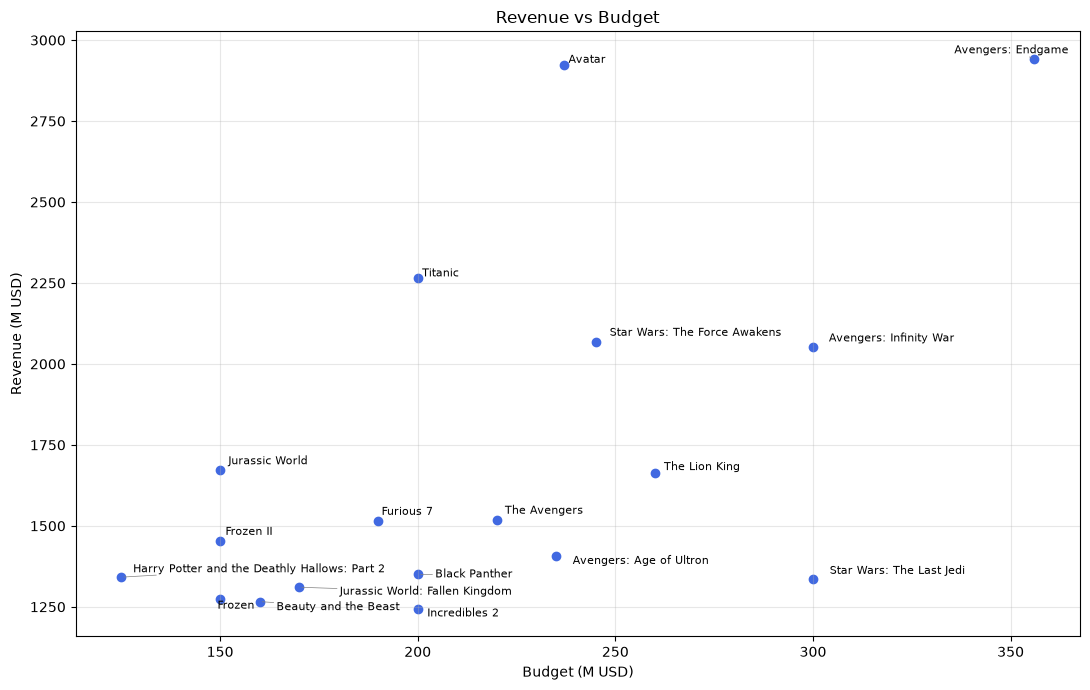

In [14]:
viz.plot_revenue_vs_budget(df)

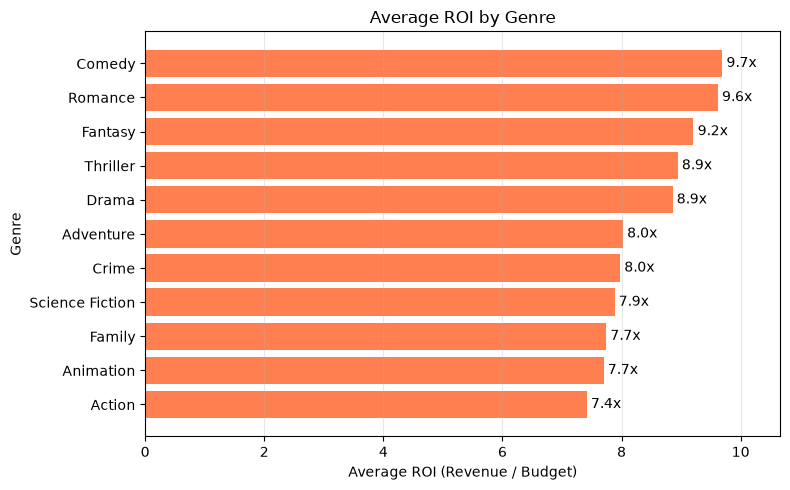

In [15]:
viz.plot_roi_by_genre(df)

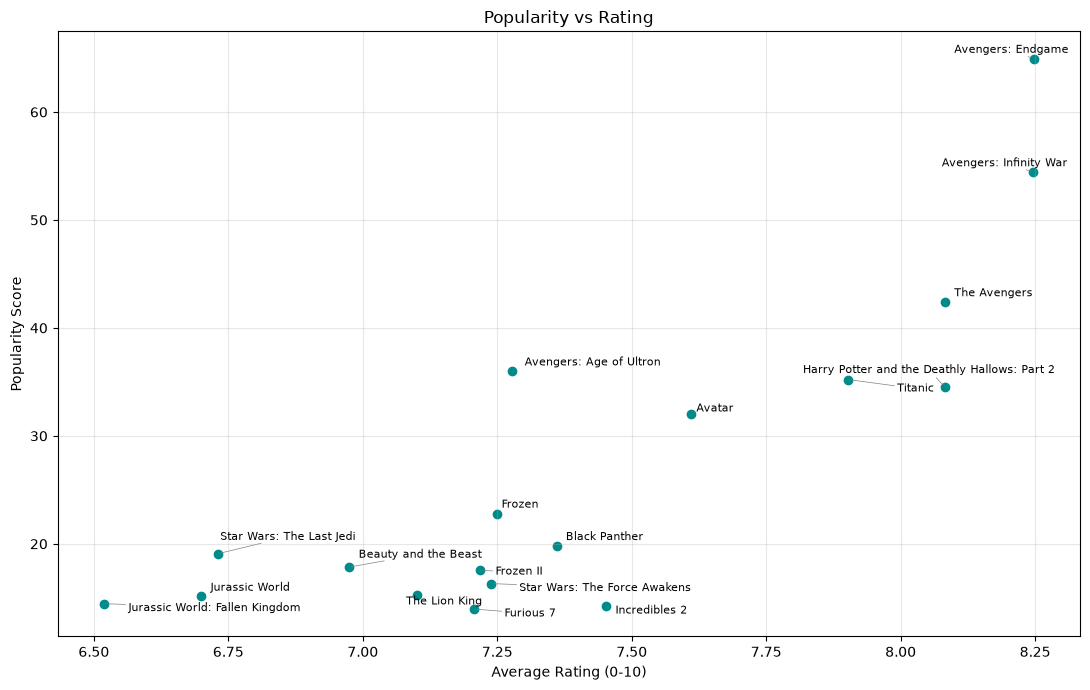

In [16]:
viz.plot_popularity_vs_rating(df)

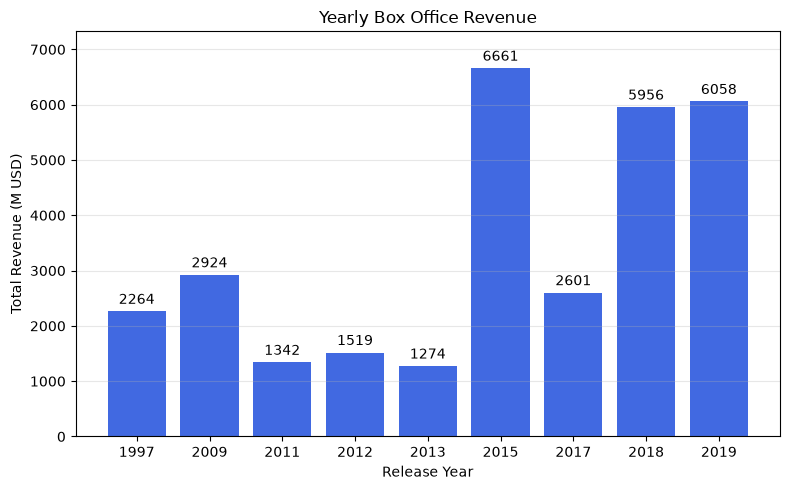

In [17]:
viz.plot_yearly_box_office(df)

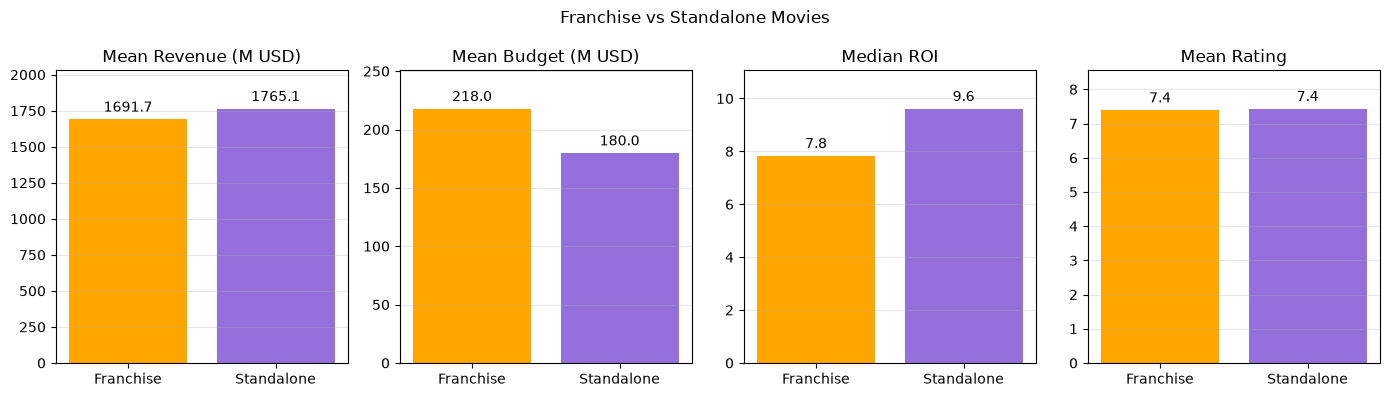

In [18]:
viz.plot_franchise_vs_standalone(comparison)

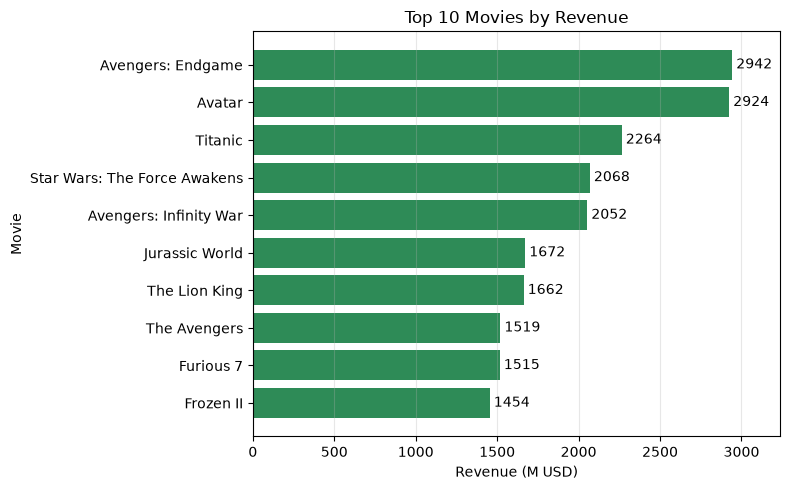

In [19]:
viz.plot_top_10_revenue(df)

In [20]:
spark.stop()